# Disc and fovea detection: research journal

A running record of the detection example: labels made by VascX on AI-READI, then box detectors trained on them.
Each part is dated; earlier parts stay as they were written, and their takeaways record what we believed at the time.

| Date | Part | Question | Answer, in one line |
|---|---|---|---|
| 2026-11-05 | 1. Labels (sections 1–7) | Are VascX's disc / fovea labels usable as training targets? | Yes: complete, anatomically sane; failures are mostly ungradable photos, removed by `q_bad <= 0.99` |
| 2026-11-06 | Discussion (before section 8) | What are the labels? | VascX outputs, not clinician labels; the fovea box is a 1 DD square around VascX's point, an approximation |
| 2026-11-06 | 2. Detectors (sections 8–14) | How well do Faster R-CNN and RetinaNet reproduce them, and where do they miss? | Both agree with VascX to ~0.93 disc / ~0.85 fovea IoU; RetinaNet 2× faster; most big misses are VascX label errors (section 14) |

Reads the data area (`$DISC_DATA`) and AI-READI (`$AIREADI_ROOT`), like the scripts. Kernel: the `vascx` env.
Part 2 also needs `python evaluate.py` (per-photo predictions → `Stats/<run>/`). Slide figures are written to the data
area's `Stats/slides/` (PNG for slides, SVG for editing), not to the repo: several show AI-READI photos.

**Before committing:** clear the outputs (*Kernel → Restart & Clear Output*): they show AI-READI photos, which the
licence doesn't let us redistribute.

# Part 1: Labels (2026-11-05)

In [1]:
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom

AIREADI_ROOT = Path(os.environ.get("AIREADI_ROOT", "/persist/public_datasets/ai_readi"))
DISC_DATA = Path(os.environ.get("DISC_DATA", "/scratch90/QTIM/Active/Non-IRB/VascX_disc_detection_and_segmentation/Data"))

cohort = pd.read_csv(DISC_DATA / "cohort.csv")
boxes = pd.read_csv(DISC_DATA / "boxes.csv").drop(columns=["height", "width"])  # cohort has them too
splits = pd.read_csv(DISC_DATA / "splits.csv")
df = cohort.merge(boxes, on="sop_instance_uid", how="left").merge(splits, on="participant_id")
df["field"] = df.device + " / " + df.region
FIELDS = sorted(df.field.unique())

# Derived geometry, used below
df["disc_w"] = df.disc_x1 - df.disc_x0
df["disc_h"] = df.disc_y1 - df.disc_y0
df["disc_cx"] = (df.disc_x0 + df.disc_x1) / 2
df["disc_cy"] = (df.disc_y0 + df.disc_y1) / 2
df["disc_diameter"] = (df.disc_w + df.disc_h) / 2
df["disc_w_frac"] = df.disc_w / df.width  # disc size relative to the photo
df["fovea_dist_dd"] = np.hypot(df.disc_cx - df.fovea_x, df.disc_cy - df.fovea_y) / df.disc_diameter
df["disc_side"] = np.where(df.disc_found == 1, np.where(df.disc_cx < df.fovea_x, "L", "R"), None)
df.head(3)

,sop_instance_uid,participant_id,device,region,laterality,height,width,filepath,disc_found,disc_x0,...,split,field,disc_w,disc_h,disc_cx,disc_cy,disc_diameter,disc_w_frac,fovea_dist_dd,disc_side
0,2.25.2320100385756307968122716024616158263792,1001,Aurora,Macula or Optic Disc,L,1776,2368,/retinal_photography/cfp/optomed_aurora/1001/1...,1,525.0,...,train,Aurora / Macula or Optic Disc,225.0,258.0,637.5,897.0,241.5,0.095017,2.859398,L
1,2.25.294574430048719510642929719225831931768,1001,Aurora,Macula or Optic Disc,L,1776,2368,/retinal_photography/cfp/optomed_aurora/1001/1...,1,1086.0,...,train,Aurora / Macula or Optic Disc,219.0,260.0,1195.5,765.0,239.5,0.092483,3.008626,L
2,2.25.2155949258508062112722378502662507575307,1001,Aurora,Macula or Optic Disc,R,1776,2368,/retinal_photography/cfp/optomed_aurora/1001/1...,1,1187.0,...,train,Aurora / Macula or Optic Disc,223.0,250.0,1298.5,864.0,236.5,0.094172,3.066315,R


Helper used throughout: draws VascX's mask outline, disc box, fovea box and point on the original photos (section 6 and on).

In [2]:
def show(rows, title="", ncols=4, width=420):
    """Draw mask outline, disc box, fovea box and point on each photo, in a grid."""
    rows = list(rows.itertuples()) if isinstance(rows, pd.DataFrame) else rows
    if not rows:
        print("nothing to show")
        return
    nrows = (len(rows) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, rows):
        rgb = np.ascontiguousarray(pydicom.dcmread(AIREADI_ROOT / r.filepath.lstrip("/")).pixel_array)
        thick = max(2, rgb.shape[1] // 300)
        mask_file = DISC_DATA / "disc_masks" / f"{r.sop_instance_uid}.png"
        if mask_file.exists():
            contours, _ = cv2.findContours(cv2.imread(str(mask_file), 0), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            cv2.drawContours(rgb, contours, -1, (0, 255, 255), thick)
        if r.disc_found == 1:
            cv2.rectangle(rgb, (int(r.disc_x0), int(r.disc_y0)), (int(r.disc_x1), int(r.disc_y1)), (0, 255, 0), thick)
            cv2.rectangle(rgb, (int(r.fovea_x0), int(r.fovea_y0)), (int(r.fovea_x1), int(r.fovea_y1)), (255, 0, 0), thick)
        if not pd.isna(r.fovea_x):
            cv2.circle(rgb, (int(r.fovea_x), int(r.fovea_y)), 3 * thick, (255, 0, 0), -1)
        ax.imshow(cv2.resize(rgb, (width, int(width * rgb.shape[0] / rgb.shape[1]))))
        ax.set_title(f"{r.field}  {r.laterality}\npeak {r.fovea_peak:.2f}  parts {r.disc_parts:.0f}  {r.participant_id}", fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()

## 1. What's there

Every cohort photo should have a row in `boxes.csv`; the split is AI-READI's own, per participant.

In [3]:
print(f"{len(df)} photos, {df.participant_id.nunique()} participants, "
      f"{df.disc_found.notna().sum()} labelled, {df.error.notna().sum()} errors")
pd.crosstab(df.field, df.split, margins=True)[["train", "val", "test", "All"]]

15611 photos, 1065 participants, 15611 labelled, 0 errors


split,train,val,test,All
field,,,,
Aurora / Macula or Optic Disc,3347,699,746,4792
Eidon / Macula,1529,325,323,2177
Maestro2 / Macula,1486,317,316,2119
"Triton / Macula, 12 x 12",1500,328,321,2149
"Triton / Macula, 6 x 6",1471,313,315,2099
Triton / Optic Disc,1586,345,344,2275
All,10919,2327,2365,15611


In [4]:
pd.crosstab(df.field, df.laterality)

laterality,L,R
field,,
Aurora / Macula or Optic Disc,2357,2435
Eidon / Macula,1067,1110
Maestro2 / Macula,1052,1067
"Triton / Macula, 12 x 12",1067,1082
"Triton / Macula, 6 x 6",1044,1055
Triton / Optic Disc,1112,1163


## 2. Did VascX find a disc?

`disc_parts > 1` means the mask has more than one blob; the box covers only the largest, so those are
worth a look.

In [5]:
summary = df.groupby("field").agg(
    photos=("sop_instance_uid", "size"),
    disc_found_pct=("disc_found", lambda s: 100 * s.mean()),
    multi_part_pct=("disc_parts", lambda s: 100 * (s > 1).mean()),
    fovea_peak_median=("fovea_peak", "median"),
    fovea_peak_low_pct=("fovea_peak", lambda s: 100 * (s < 0.5).mean()),
)
summary.round(2)

,photos,disc_found_pct,multi_part_pct,fovea_peak_median,fovea_peak_low_pct
field,,,,,
Aurora / Macula or Optic Disc,4792,96.83,3.61,0.97,0.31
Eidon / Macula,2177,98.62,1.65,0.98,0.00
Maestro2 / Macula,2119,99.43,0.38,0.99,0.14
"Triton / Macula, 12 x 12",2149,99.49,0.33,0.99,0.09
"Triton / Macula, 6 x 6",2099,99.57,0.14,0.99,0.00
Triton / Optic Disc,2275,99.96,0.04,0.98,0.04


## 3. Box size and shape

The disc's size relative to the photo depends on the camera's field of view, so each device gets its own
distribution. Discs are slightly taller than wide, so a width / height a bit under 1 is expected.

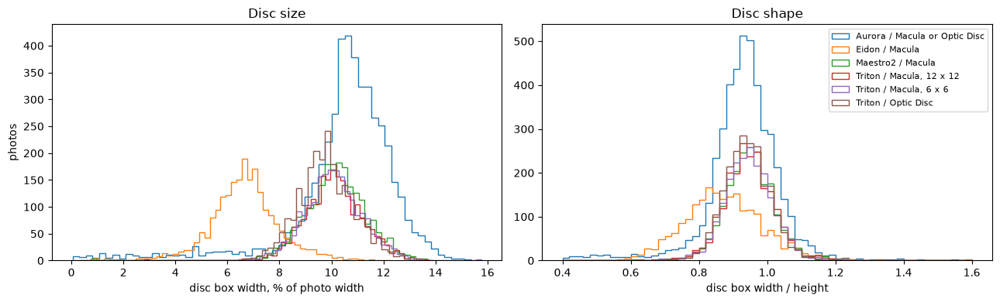

In [6]:
found = df[df.disc_found == 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for field in FIELDS:
    sub = found[found.field == field]
    axes[0].hist(100 * sub.disc_w_frac, bins=60, histtype="step", label=field)
    axes[1].hist(sub.disc_w / sub.disc_h, bins=60, range=(0.4, 1.6), histtype="step", label=field)
axes[0].set(xlabel="disc box width, % of photo width", ylabel="photos", title="Disc size")
axes[1].set(xlabel="disc box width / height", title="Disc shape")
axes[1].legend(fontsize=8)
plt.tight_layout()

## 4. Where are the disc and the fovea?

Centres in relative photo coordinates (0–1), for 150 photos per field. A line joins each photo's disc (circle) to its fovea
(cross), blue for left eyes, orange for right. Clusters from *different* photos can overlap: in Aurora, disc-centred
shots put the disc in the middle and macula-centred shots put the fovea there. Within one photo the two are always
apart (see the distance below).

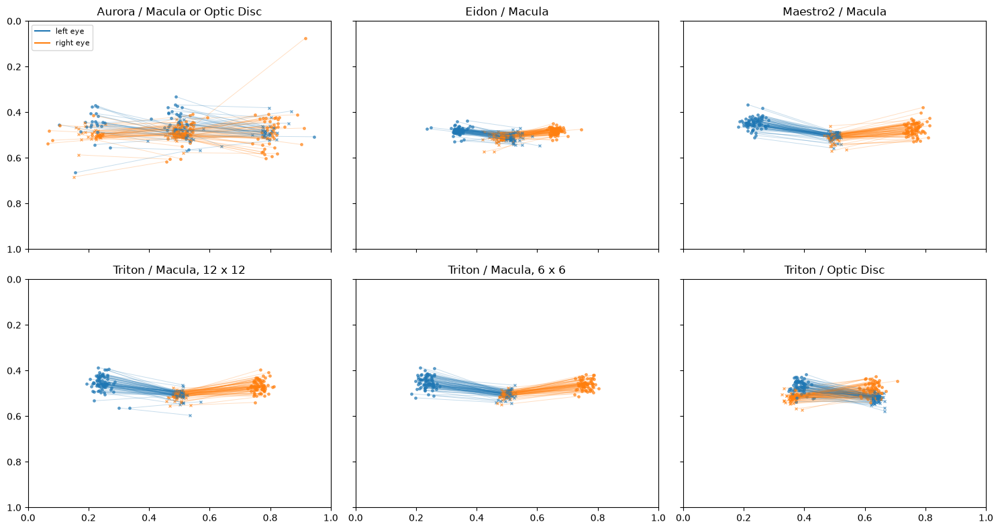

In [7]:
found = df[df.disc_found == 1]
EYE_COLOUR = {"L": "tab:blue", "R": "tab:orange"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, field in zip(axes.flat, FIELDS):
    sub = found[found.field == field].sample(150, random_state=0)
    for r in sub.itertuples():
        colour = EYE_COLOUR[r.laterality]
        ax.plot([r.disc_cx / r.width, r.fovea_x / r.width], [r.disc_cy / r.height, r.fovea_y / r.height],
                color=colour, alpha=0.25, lw=0.7)
        ax.plot(r.disc_cx / r.width, r.disc_cy / r.height, "o", color=colour, ms=2.5, alpha=0.6)
        ax.plot(r.fovea_x / r.width, r.fovea_y / r.height, "x", color=colour, ms=3, alpha=0.6)
    ax.set(title=field, xlim=(0, 1), ylim=(1, 0))
axes[0, 0].plot([], [], color="tab:blue", label="left eye")
axes[0, 0].plot([], [], color="tab:orange", label="right eye")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()

Disc-to-fovea distance in disc diameters: anatomy says about 2.5. Values far from that point to a
wrong disc or a wrong fovea.

0.01    1.90
0.05    2.18
0.50    2.62
0.95    3.45
0.99    8.34


[Text(0.5, 0, 'disc-to-fovea distance, disc diameters (clipped at 8)'),
 Text(0, 0.5, 'photos')]

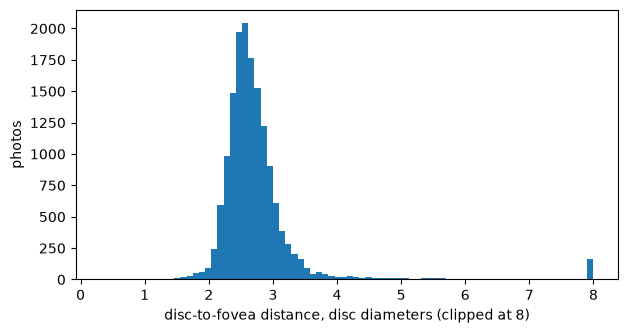

In [8]:
print(found.fovea_dist_dd.quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(found.fovea_dist_dd.clip(upper=8), bins=80)
ax.set(xlabel="disc-to-fovea distance, disc diameters (clipped at 8)", ylabel="photos")

## 5. Check against laterality

In a left eye's photo the disc sits to the left of the fovea; in a right eye, to the right. AI-READI records
laterality independently of VascX, so a disagreement means VascX got the disc or the fovea wrong, or the photo is
unusual (e.g. disc-centred with the fovea out of view).

In [9]:
found = df[df.disc_found == 1]
disagree = found[found.disc_side != found.laterality]
print(f"{len(disagree)} of {len(found)} disagree ({100 * len(disagree) / len(found):.1f} %)")
pd.DataFrame({"photos": found.field.value_counts(), "disagree": disagree.field.value_counts()}).fillna(0).astype(int).assign(
    pct=lambda t: (100 * t.disagree / t.photos).round(1))

229 of 15396 disagree (1.5 %)


,photos,disagree,pct
field,,,
Aurora / Macula or Optic Disc,4640,209,4.5
Eidon / Macula,2147,7,0.3
Maestro2 / Macula,2107,8,0.4
"Triton / Macula, 12 x 12",2138,2,0.1
"Triton / Macula, 6 x 6",2090,1,0.0
Triton / Optic Disc,2274,2,0.1


## 5b. Image quality (VascX's quality model)

`make_quality.py` rates every photo good / usable / bad with VascX's EyePACS-trained classifier. "Bad" there means
*ungradable for diabetic retinopathy*, which is stricter than "the disc is visible", so we look before choosing a cut-off:
how quality relates to our failure signals (no disc, laterality disagreement), per field.

In [10]:
quality_file = DISC_DATA / "quality.csv"
if quality_file.exists():
    df = df.drop(columns=[c for c in ["q_good", "q_usable", "q_bad", "quality"] if c in df], errors="ignore").merge(
        pd.read_csv(quality_file).drop(columns="error"), on="sop_instance_uid", how="left")
    df["disagree"] = (df.disc_found == 1) & (df.disc_side != df.laterality)
    display(pd.crosstab(df.field, df.quality, margins=True)[["good", "usable", "bad", "All"]])
    display(df.groupby("quality").agg(photos=("sop_instance_uid", "size"),
                                      no_disc_pct=("disc_found", lambda s: 100 * (s == 0).mean()),
                                      disagree_pct=("disagree", lambda s: 100 * s.mean())).round(2).loc[["good", "usable", "bad"]])
else:
    print("no quality.csv yet: run python make_quality.py")

quality,good,usable,bad,All
field,,,,
Aurora / Macula or Optic Disc,402,1312,3078,4792
Eidon / Macula,1350,15,812,2177
Maestro2 / Macula,1846,152,121,2119
"Triton / Macula, 12 x 12",1684,309,156,2149
"Triton / Macula, 6 x 6",1750,217,132,2099
Triton / Optic Disc,1920,263,92,2275
All,8952,2268,4391,15611


,photos,no_disc_pct,disagree_pct
quality,,,
good,8952,0.08,0.08
usable,2268,0.00,0.13
bad,4391,4.74,4.99


Failure rate against `q_bad`: if failures pile up only at the very top, a high cut-off drops the junk
and keeps hazy-but-usable disc photos.

,photos,no_disc_pct,disagree_pct
q_bad_bin,,,
"(-0.001, 0.5]",11271,0.06,0.09
"(0.5, 0.9]",1581,0.13,0.13
"(0.9, 0.99]",1142,0.88,0.53
"(0.99, 0.999]",689,2.76,3.19
"(0.999, 1.0]",928,19.07,20.37


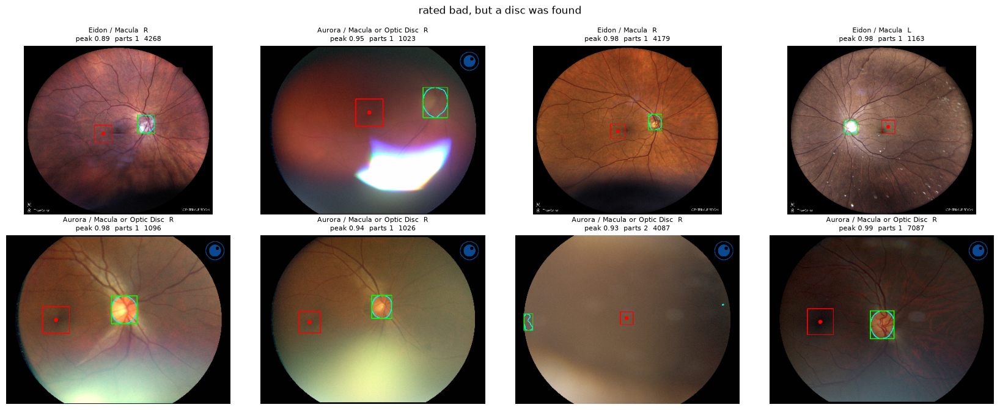

In [11]:
if "q_bad" in df:
    bins = [0, 0.5, 0.9, 0.99, 0.999, 1.0]
    df["q_bad_bin"] = pd.cut(df.q_bad, bins, include_lowest=True)
    display(df.groupby("q_bad_bin", observed=True).agg(photos=("sop_instance_uid", "size"),
                                                     no_disc_pct=("disc_found", lambda s: 100 * (s == 0).mean()),
                                                     disagree_pct=("disagree", lambda s: 100 * s.mean())).round(2))
    show(df[(df.quality == "bad") & (df.disc_found == 1)].sample(8, random_state=0), "rated bad, but a disc was found")

## 6. Look at the photos

Cyan outline: the disc mask. Green: disc box. Red: fovea box, with a dot at the fovea point.

### A random sample per field

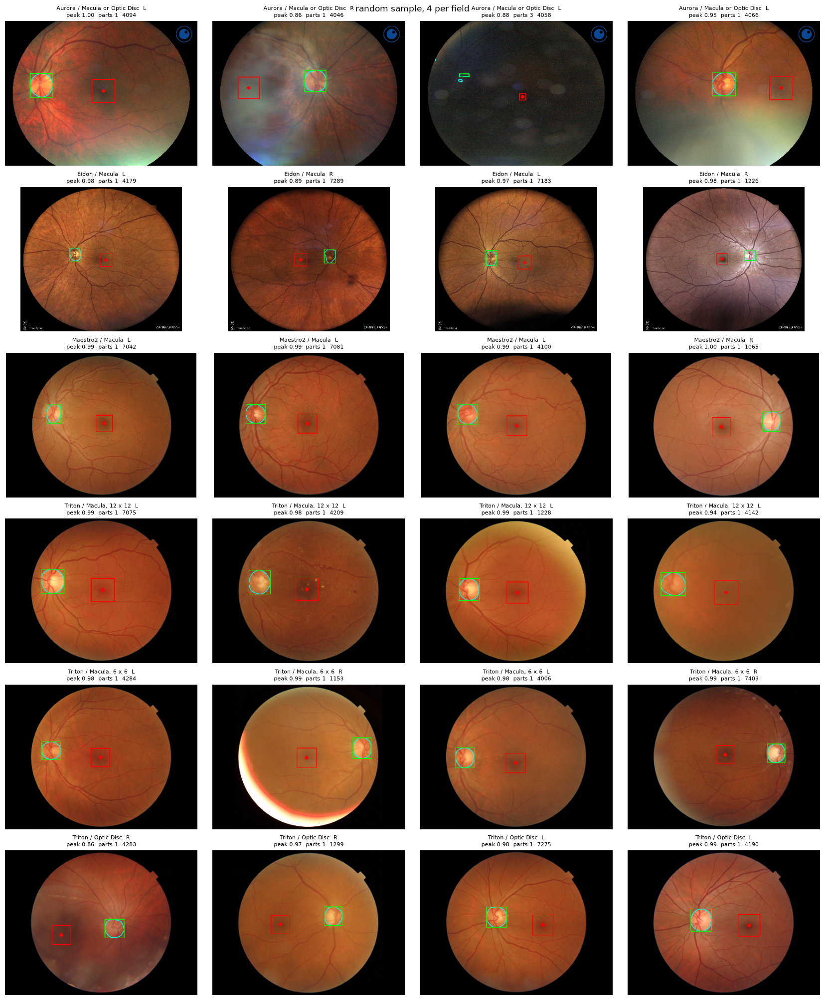

In [12]:
sample = df[df.disc_found == 1].groupby("field").sample(4, random_state=0)
show(sample, "random sample, 4 per field")

### Laterality disagreements

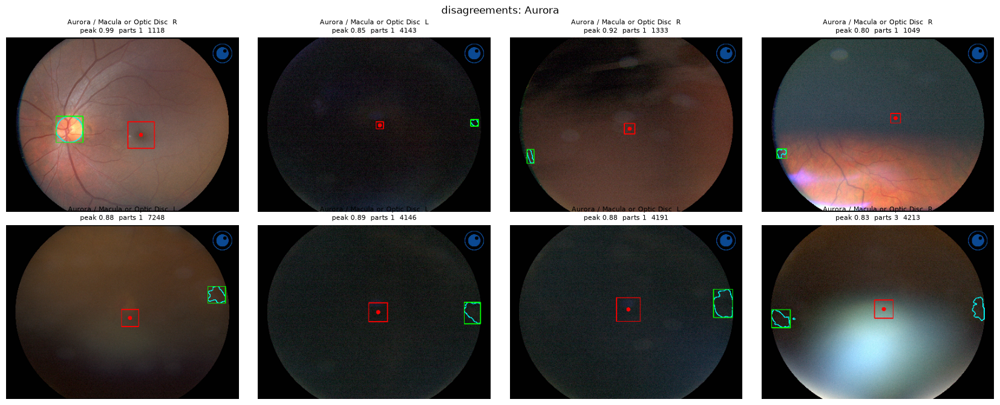

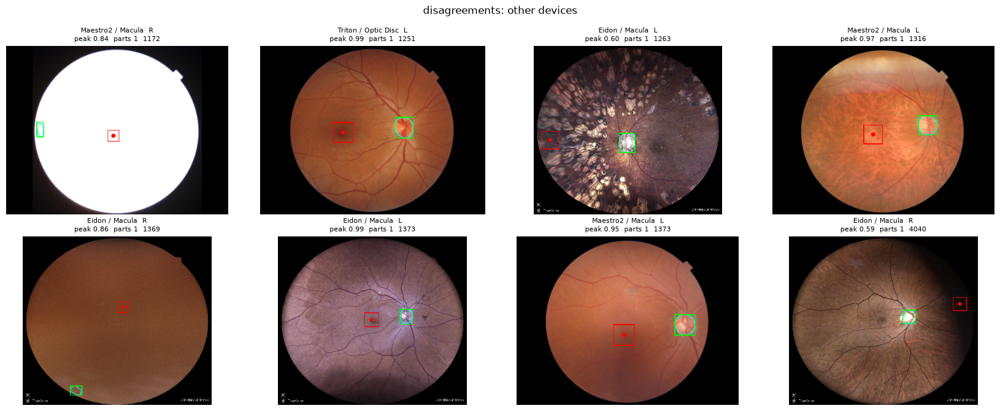

In [13]:
show(disagree[disagree.field.str.startswith("Aurora")].sample(8, random_state=0), "disagreements: Aurora")
show(disagree[~disagree.field.str.startswith("Aurora")].head(8), "disagreements: other devices")

### No disc found

field
Aurora / Macula or Optic Disc    152
Eidon / Macula                    30
Maestro2 / Macula                 12
Triton / Macula, 12 x 12          11
Triton / Macula, 6 x 6             9
Triton / Optic Disc                1


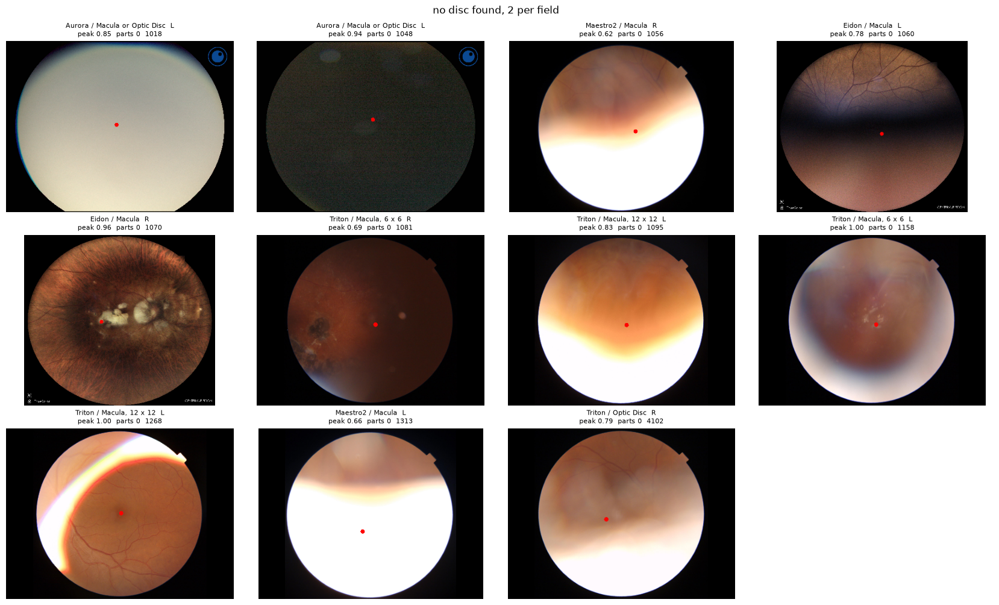

In [14]:
no_disc = df[df.disc_found == 0]
print(no_disc.field.value_counts().to_string())
show(no_disc.groupby("field").head(2), "no disc found, 2 per field")

### Odd ones: several disc blobs, low fovea confidence, odd disc-fovea distance

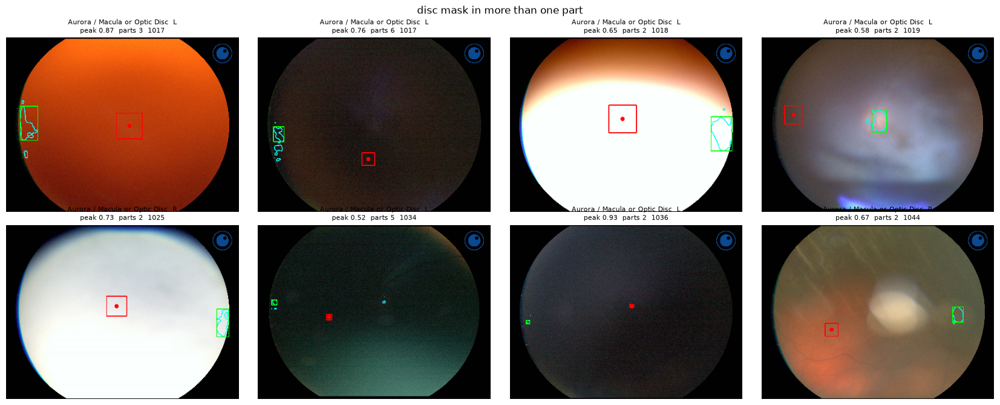

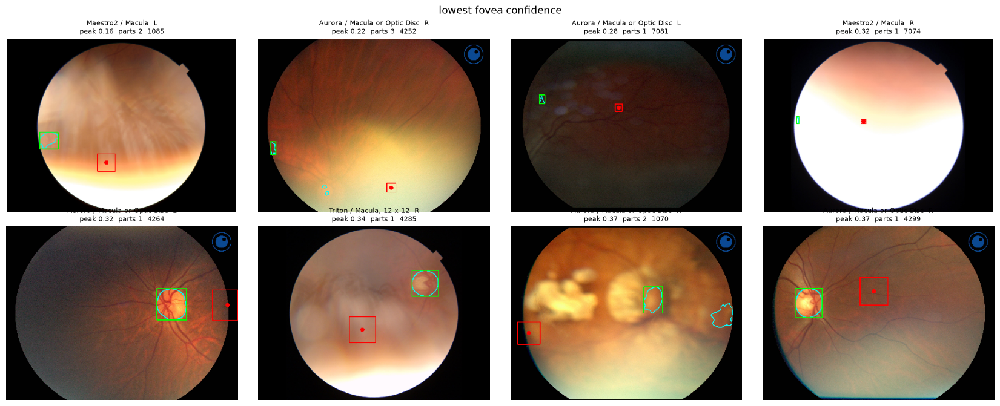

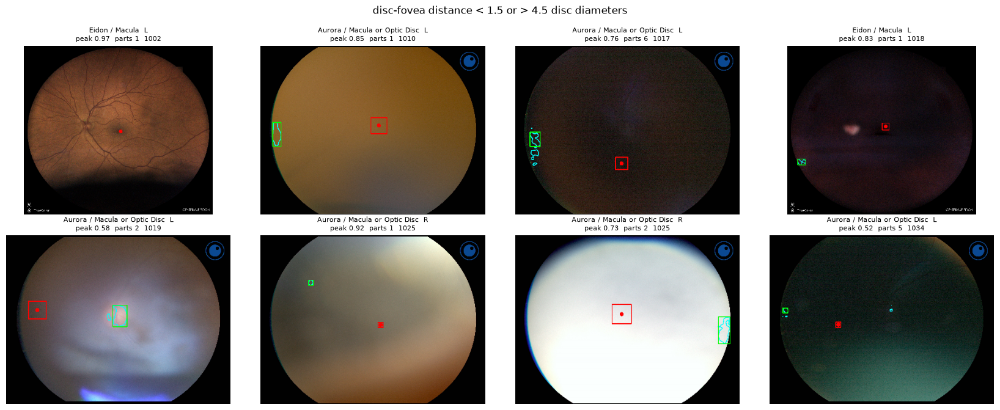

In [15]:
show(df[df.disc_parts > 1].head(8), "disc mask in more than one part")
show(df.nsmallest(8, "fovea_peak"), "lowest fovea confidence")
show(found[(found.fovea_dist_dd < 1.5) | (found.fovea_dist_dd > 4.5)].head(8), "disc-fovea distance < 1.5 or > 4.5 disc diameters")

## 7. Takeaways (first look, 2026-11-05)

- **Complete.** All 15,611 photos are labelled, with no read or crop errors. VascX finds a disc in 96.8 % (Aurora) to
  99.96 % (Triton disc) of them.
- **Anatomy checks out.** The median disc-to-fovea distance is 2.6 disc diameters (textbook about 2.5). Disc boxes are slightly
  taller than wide. Each device's disc and fovea cluster where its framing puts them (section 4).
- **Aurora is two framings in one.** "Macula or Optic Disc" mixes macula-centred photos (disc to one side) with
  disc-centred ones (disc in the middle). That's fine for a detector, but it's why Aurora's clusters look busier.
- **Most failures are bad photos, not bad models.** Aurora's laterality disagreements (4.5 %) and most "no disc"
  photos are very dark, washed-out or obstructed. On these VascX sometimes puts a "disc" at the rim. The other
  devices disagree in 0.0–0.4 % of photos.
- **Some disagreements look like AI-READI laterality errors.** Several are clear photos where VascX's disc and
  fovea are plainly right but the disc is on the "wrong" side for the recorded eye. The detector doesn't use
  laterality, so this only matters as a QA signal.
- **A few real misses.** Heavy pathology (large lesions) can pull the fovea point, or make the disc go unfound.

**Before training:** drop ungradable photos. VascX ships a `quality` model that could do this, or a simple rule:
drop laterality disagreements and `disc_parts > 1`. Keep "no disc" photos only where the photo is gradable (they're
true negatives). Then decide whether Aurora's disc-centred photos stay in.

# Part 2: Detectors (2026-11-06)

Two torchvision detectors trained by `train.py` on the same cache, split, filter and labels (2026-11-05, 20 epochs each,
one GPU each): **Faster R-CNN** (two-stage) and **RetinaNet** (one-stage). Labels are VascX's boxes, so everything below
measures *agreement with VascX*, not truth. A hand-checked sample is still to do.

Metrics, per class, using the top-scoring box: **IoU** with the VascX box, **hit50** (share with IoU ≥ 0.5), and the
**centre error** in disc diameters (DD; 1 DD ≈ 1.5 mm). Clinically the centre error is the one that matters: a
fovea within 0.5 DD is within the central macula.

`evaluate.py` re-ran each run's `best.pt` on *every* test photo (also the ones the filter drops) and saved the top boxes.
This section reads those files; nothing here runs a model.

In [16]:
import json

import matplotlib.ticker as mticker
from matplotlib.patches import Rectangle

MODELS_DIR = DISC_DATA.parent / "Models"
STATS = DISC_DATA.parent / "Stats"
SLIDES = STATS / "slides"
SLIDES.mkdir(parents=True, exist_ok=True)
CACHE_IMAGES = np.load(DISC_DATA / "cache_512" / "images.npy", mmap_mode="r")

# The latest run of each architecture
RUNS = {}
for run in sorted(MODELS_DIR.glob("*_*")):
    if (run / "test.csv").exists():
        RUNS[run.name.split("_")[0]] = run
NAMES = {"fasterrcnn": "Faster R-CNN", "retinanet": "RetinaNet"}
ARCHS = list(RUNS)

# Look: categorical slots 1-2 of the dataviz reference palette (the same blue as VascX_App/slides)
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLOUR = {"fasterrcnn": "#2a78d6", "retinanet": "#eb6834"}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "legend.frameon": False, "font.family": "DejaVu Sans"})


def save(fig, name):
    """Slide copy of a figure: PNG (200 dpi) for the deck, SVG for editing."""
    for ext in ("png", "svg"):
        fig.savefig(SLIDES / f"{name}.{ext}", dpi=200, bbox_inches="tight")


def iou(p, g):
    """Row-wise IoU of two (N, 4) box arrays; NaN boxes give NaN."""
    ix = np.clip(np.minimum(p[:, 2], g[:, 2]) - np.maximum(p[:, 0], g[:, 0]), 0, None)
    iy = np.clip(np.minimum(p[:, 3], g[:, 3]) - np.maximum(p[:, 1], g[:, 1]), 0, None)
    inter = ix * iy
    area = lambda b: (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area(p) + area(g) - inter)


def scored(arch):
    """Per-photo predictions with IoU and centre error (disc diameters), as train.py computes them."""
    p = pd.read_csv(STATS / RUNS[arch].name / "test_predictions.csv")
    g_disc = p[[f"gt_disc_{c}" for c in ("x0", "y0", "x1", "y1")]].to_numpy()
    dd = ((g_disc[:, 2] - g_disc[:, 0]) + (g_disc[:, 3] - g_disc[:, 1])) / 2
    for name in ("disc", "fovea"):
        pr = p[[f"{name}_{c}" for c in ("x0", "y0", "x1", "y1")]].to_numpy()
        gt = p[[f"gt_{name}_{c}" for c in ("x0", "y0", "x1", "y1")]].to_numpy()
        p[f"{name}_iou"] = np.where(np.isnan(pr[:, 0]), 0.0, iou(pr, gt))  # no box = IoU 0, like train.py
        p.loc[np.isnan(gt[:, 0]), f"{name}_iou"] = np.nan                  # no VascX box = nothing to compare
        centre = lambda b: np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2]
        p[f"{name}_centre_dd"] = np.linalg.norm(centre(pr) - centre(gt), axis=1) / dd
    return p


pred = {a: scored(a) for a in ARCHS}
kept = {a: p[p.kept] for a, p in pred.items()}
print({NAMES[a]: RUNS[a].name for a in ARCHS})
print(f"test photos: {len(pred[ARCHS[0]])}, kept by the filter: {len(kept[ARCHS[0]])}")

{'Faster R-CNN': 'fasterrcnn_20261105-151050', 'RetinaNet': 'retinanet_20261105-151050'}
test photos: 2365, kept by the filter: 2046


## Discussion: what the labels are, and aren't (2026-11-06)

Every number in Part 2 is **agreement with VascX**, not accuracy against clinicians. The labels are good guesses from a published
model, checked in Part 1 for completeness and anatomy, but **no clinician drew or reviewed them**.

- **Disc box**: the tight box around VascX's disc *segmentation* (largest piece of the mask). A real model output, so disc IoU
  is a meaningful measure of agreement with VascX's disc boundary.
- **Fovea box**: VascX gives only a **point** (heatmap peak). The box is ours: a square centred on that point, **one disc diameter
  (DD) wide and tall**. The fovea has no visible edge, so the box's size is a convention, not anatomy. It exists only because a box
  detector needs box targets.
- **Consequences.** (1) Fovea IoU measures the detector's agreement with a convention, and partly how well it guesses the disc's size
  (it must, to size the square); read it as a training check. (2) The meaningful fovea number is the **centre error in DD**: the
  detector's box centre vs VascX's point. (3) Where VascX is wrong, a detector that disagrees is scored as wrong (section 11 shows
  this happening on Eidon). (4) Nothing here tells us how VascX itself compares with a clinician.
- **Why DD as the unit.** Pixels aren't comparable across devices (fields of view differ); discs are similar in size across people
  (~1.5–1.9 mm) and visible in every photo, so DD is a ruler built into each image. Clinicians use it too (disc to fovea ≈ 2.5 DD).
  Millimetres would need a reliable per-device pixel size, which these DICOMs don't consistently give.

**To close the gap:** a clinician-reviewed sample (accept / correct the disc box and the fovea point), and a point-based fovea
model (keypoint or heatmap) so no square is needed.

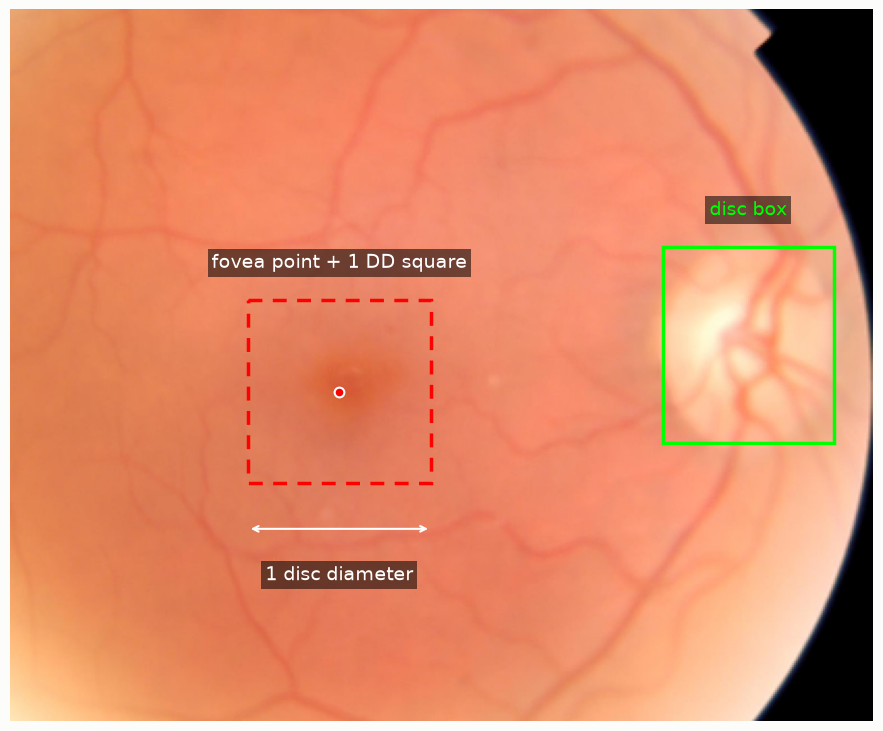

In [17]:
# How one label is built: VascX disc mask -> disc box; VascX fovea point -> 1 DD square
r = kept[ARCHS[0]].query("field == 'Maestro2 / Macula'").iloc[3]
img = CACHE_IMAGES[int(r.row)]
d = [r.gt_disc_x0, r.gt_disc_y0, r.gt_disc_x1, r.gt_disc_y1]
f = [r.gt_fovea_x0, r.gt_fovea_y0, r.gt_fovea_x1, r.gt_fovea_y1]
dd = ((d[2] - d[0]) + (d[3] - d[1])) / 2
fx, fy = (f[0] + f[2]) / 2, (f[1] + f[3]) / 2
pad = 1.3 * dd
x0, x1 = min(d[0], f[0]) - pad, max(d[2], f[2]) + pad
y0, y1 = min(d[1], f[1]) - pad, max(d[3], f[3]) + pad
x0, x1, y0, y1 = max(x0, 0), min(x1, img.shape[1]), max(y0, 0), min(y1, img.shape[0])  # stay inside the crop
fig, ax = plt.subplots(figsize=(9, 9 * (y1 - y0) / (x1 - x0)))
ax.imshow(img)
ax.set(xlim=(x0, x1), ylim=(y1, y0))
ax.axis("off")
ax.add_patch(Rectangle(d[:2], d[2] - d[0], d[3] - d[1], fill=False, ec="lime", lw=2.5))
ax.add_patch(Rectangle(f[:2], f[2] - f[0], f[3] - f[1], fill=False, ec="red", lw=2.5, ls=(0, (4, 3))))
ax.plot(fx, fy, "o", color="red", ms=7, mec="white", mew=1.5)
ax.annotate("", xy=(f[0], f[3] + 0.25 * dd), xytext=(f[2], f[3] + 0.25 * dd), arrowprops=dict(arrowstyle="<->", color="white", lw=1.5))
ax.text(fx, f[3] + 0.45 * dd, "1 disc diameter", color="white", ha="center", va="top", fontsize=14, bbox=dict(facecolor="black", alpha=0.55, lw=0, pad=3))
box = dict(facecolor="black", alpha=0.55, lw=0, pad=3)
ax.text((d[0] + d[2]) / 2, d[1] - 0.15 * dd, "disc box", color="lime", fontsize=14, ha="center", va="bottom", bbox=box)
ax.text(fx, f[1] - 0.15 * dd, "fovea point + 1 DD square", color="white", fontsize=14, ha="center", va="bottom", bbox=box)
fig.tight_layout()
save(fig, "fig0_label_construction")

## 8. Training

Same settings for both: 512 × 512 crops, batch 8, AdamW 1e-4 with cosine decay, 20 epochs, COCO-pretrained, flips and mild
brightness / contrast jitter. `best.pt` is the epoch with the best mean val IoU (disc + fovea).

In [18]:
config = pd.DataFrame({NAMES[a]: json.loads((RUNS[a] / "config.json").read_text()) for a in ARCHS}).T
logs = {a: pd.read_csv(RUNS[a] / "log.csv") for a in ARCHS}
for a in ARCHS:
    best = logs[a].assign(score=lambda t: (t.disc_iou + t.fovea_iou) / 2).score.idxmax()
    config.loc[NAMES[a], "best epoch"] = int(logs[a].epoch[best])
config[["epochs", "batch_size", "lr", "q_bad_max", "photos", "best epoch"]]

,epochs,batch_size,lr,q_bad_max,photos,best epoch
Faster R-CNN,20,8,0.0001,0.99,"{'train': 9817, 'val': 2064, 'test': 2046}",20.0
RetinaNet,20,8,0.0001,0.99,"{'train': 9817, 'val': 2064, 'test': 2046}",19.0


Validation curves. The training losses aren't comparable across the two (different loss functions), so only the val
metrics are plotted. Both flatten by about epoch 10; the remaining epochs buy a little fovea IoU.

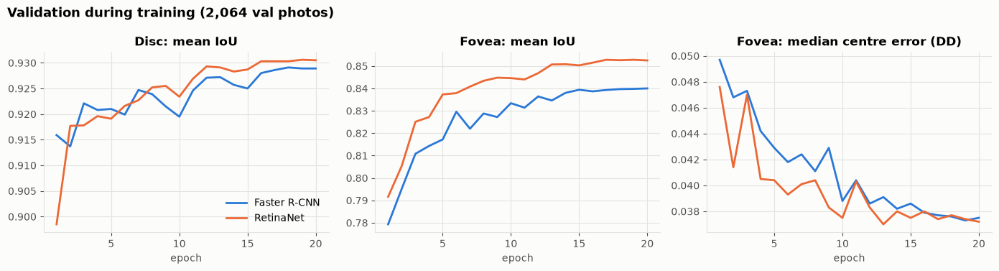

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
panels = [("disc_iou", "Disc: mean IoU"), ("fovea_iou", "Fovea: mean IoU"), ("fovea_centre_dd", "Fovea: median centre error (DD)")]
for ax, (col, title) in zip(axes, panels):
    for a in ARCHS:
        ax.plot(logs[a].epoch, logs[a][col], color=COLOUR[a], lw=2, label=NAMES[a])
    ax.set(title=title, xlabel="epoch")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
axes[0].legend(loc="lower right")
fig.suptitle("Validation during training (2,064 val photos)", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "fig1_training_curves")

## 9. Test results

First a sanity check: metrics recomputed from the saved per-photo predictions must match `train.py`'s `test.csv`
(same photos, same rule). Then the headline numbers, with speed from `evaluate.py` (batch 16, one RTX A4000).

In [20]:
def summary(p):
    out = {"photos": len(p)}
    for n in ("disc", "fovea"):
        out[f"{n}_iou"] = p[f"{n}_iou"].mean()
        out[f"{n}_hit50"] = (p[f"{n}_iou"] >= 0.5).mean()
        out[f"{n}_centre_dd"] = p[f"{n}_centre_dd"].median()
        out[f"{n}_within_0.5dd"] = (p[f"{n}_centre_dd"] <= 0.5).mean()
    return out


for a in ARCHS:
    mine = pd.Series(summary(kept[a]))
    theirs = pd.read_csv(RUNS[a] / "test.csv").set_index("field").loc["all"]
    cols = ["disc_iou", "fovea_iou", "disc_hit50", "fovea_hit50"]
    diff = (mine[cols].astype(float) - theirs[cols]).abs().max()
    print(f"{NAMES[a]}: max difference to test.csv = {diff:.4f}  {'OK' if diff < 0.002 else 'CHECK'}")

speed = {a: json.loads((STATS / RUNS[a].name / "test_speed.json").read_text()) for a in ARCHS}
headline = pd.DataFrame({NAMES[a]: summary(kept[a]) | {"photos_per_s": speed[a]["photos_per_s"],
                                                       "checkpoint_MB": round((RUNS[a] / "best.pt").stat().st_size / 1e6)}
                         for a in ARCHS}).T
headline.round(4)

Faster R-CNN: max difference to test.csv = 0.0000  OK
RetinaNet: max difference to test.csv = 0.0005  OK


,photos,disc_iou,disc_hit50,disc_centre_dd,disc_within_0.5dd,fovea_iou,fovea_hit50,fovea_centre_dd,fovea_within_0.5dd,photos_per_s,checkpoint_MB
Faster R-CNN,2046.0,0.9354,0.9946,0.0103,0.9990,0.8393,0.9560,0.0382,0.9888,37.1,173.0
RetinaNet,2046.0,0.9350,0.9961,0.0109,0.9985,0.8522,0.9575,0.0383,0.9878,80.6,146.0


Per device. Mean IoU hides the shape of the errors, so the second panel shows the share of photos with the fovea
within 0.5 DD of VascX's. One device stands out.

model                         Faster R-CNN                              \
                                  disc_iou disc_within_0.5dd fovea_iou   
field                                                                    
Aurora / Macula or Optic Disc        0.957             1.000     0.821   
Eidon / Macula                       0.794             0.993     0.641   
Maestro2 / Macula                    0.959             1.000     0.901   
Triton / Macula, 12 x 12             0.960             1.000     0.892   
Triton / Macula, 6 x 6               0.963             1.000     0.898   
Triton / Optic Disc                  0.961             1.000     0.884   

model                                                   RetinaNet  \
                              fovea_within_0.5dd photos  disc_iou   
field                                                               
Aurora / Macula or Optic Disc              0.988  481.0     0.956   
Eidon / Macula                             0.950  301.0     0.795   
Maestro2 / Macula                          1.000  307.0     0.958   
Triton / Macula, 12 x 12                   1.000  310.0     0.962   
Triton / Macula, 6 x 6                     1.000  306.0     0.962   
Triton / Optic Disc                        0.994  341.0     0.959   

model                                                                         \
                              disc_within_0.5dd fovea_iou fovea_within_0.5dd   
field                                                                          
Aurora / Macula or Optic Disc              1.00     0.826              0.981   
Eidon / Macula                             0.99     0.653              0.950   
Maestro2 / Macula                          1.00     0.919              1.000   
Triton / Macula, 12 x 12                   1.00     0.905              1.000   
Triton / Macula, 6 x 6                     1.00     0.912              1.000   
Triton / Optic Disc                        1.00     0.903              0.997   

model                                 
                              photos  
field                                 
Aurora / Macula or Optic Disc  481.0  
Eidon / Macula                 301.0  
Maestro2 / Macula              307.0  
Triton / Macula, 12 x 12       310.0  
Triton / Macula, 6 x 6         306.0  
Triton / Optic Disc            341.0

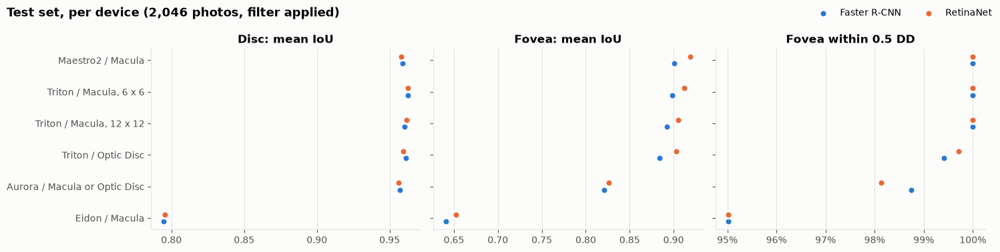

In [21]:
by_field = pd.concat({NAMES[a]: kept[a].groupby("field").apply(lambda g: pd.Series(summary(g)), include_groups=False)
                      for a in ARCHS}, names=["model", "field"])
display(by_field[["photos", "disc_iou", "fovea_iou", "disc_within_0.5dd", "fovea_within_0.5dd"]].round(3)
        .unstack("model").swaplevel(axis=1).sort_index(axis=1))

order = by_field.xs(NAMES[ARCHS[0]]).sort_values("fovea_iou").index
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
panels = [("disc_iou", "Disc: mean IoU"), ("fovea_iou", "Fovea: mean IoU"), ("fovea_within_0.5dd", "Fovea within 0.5 DD")]
y = np.arange(len(order))
for ax, (col, title) in zip(axes, panels):
    for k, a in enumerate(ARCHS):
        vals = by_field.xs(NAMES[a]).loc[order, col]
        ax.scatter(vals, y + (k - 0.5) * 0.22, s=60, color=COLOUR[a], edgecolor=SURFACE, linewidth=2, zorder=3,
                   label=NAMES[a])
    ax.set(title=title, yticks=y, yticklabels=order)
    ax.grid(axis="y", visible=False)
    if "within" in col:
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    else:
        ax.xaxis.set_major_locator(mticker.MultipleLocator(0.05))
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.suptitle("Test set, per device (2,046 photos, filter applied)", x=0.01, ha="left", fontsize=13, weight="bold")
fig.tight_layout()
save(fig, "fig2_per_device")

## 10. How big are the misses?

Cumulative share of test photos by centre error. A curve that hugs the left edge is good; the tail on the right is where
the detector disagrees with VascX. Dashed lines: 0.25 and 0.5 DD.

Faster R-CNN  fovea > 0.5 DD:  21   disc > 0.5 DD:   2   no fovea box: 2   two confident fovea boxes: 12
RetinaNet     fovea > 0.5 DD:  23   disc > 0.5 DD:   3   no fovea box: 2   two confident fovea boxes: 11


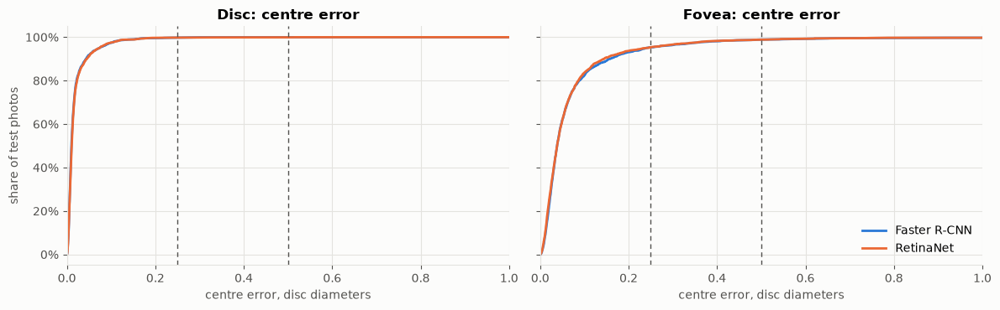

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, name in zip(axes, ("disc", "fovea")):
    for a in ARCHS:
        err = np.sort(kept[a][f"{name}_centre_dd"].fillna(np.inf).to_numpy())
        ax.plot(err, np.arange(1, len(err) + 1) / len(err), color=COLOUR[a], lw=2, label=NAMES[a])
    for x in (0.25, 0.5):
        ax.axvline(x, color=INK_2, lw=1, ls=(0, (4, 3)))
    ax.set(title=f"{name.capitalize()}: centre error", xlabel="centre error, disc diameters", xlim=(0, 1))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].set_ylabel("share of test photos")
axes[1].legend(loc="lower right")
fig.tight_layout()
save(fig, "fig3_centre_error_cdf")

for a in ARCHS:
    k = kept[a]
    print(f"{NAMES[a]:13s} fovea > 0.5 DD: {(k.fovea_centre_dd > 0.5).sum():3d}   disc > 0.5 DD: {(k.disc_centre_dd > 0.5).sum():3d}"
          f"   no fovea box: {k.fovea_score.isna().sum()}   two confident fovea boxes: {(k.fovea_n > 1).sum()}")

Do the two detectors miss the *same* photos? If they do, the photo (or VascX's label) is the problem, not the
architecture.

In [23]:
a, b = ARCHS
both = kept[a][["sop_instance_uid", "field", "row", "fovea_centre_dd", "disc_centre_dd"]].merge(
    kept[b][["sop_instance_uid", "fovea_centre_dd", "disc_centre_dd"]], on="sop_instance_uid", suffixes=(f"_{a}", f"_{b}"))
for name in ("fovea", "disc"):
    miss_a, miss_b = both[f"{name}_centre_dd_{a}"] > 0.5, both[f"{name}_centre_dd_{b}"] > 0.5
    print(f"{name}: misses (> 0.5 DD)  {NAMES[a]} {miss_a.sum()},  {NAMES[b]} {miss_b.sum()},  both {(miss_a & miss_b).sum()}")
pd.crosstab(both.field, (both[f"fovea_centre_dd_{a}"] > 0.5) & (both[f"fovea_centre_dd_{b}"] > 0.5),
            margins=True).rename(columns={True: "both miss fovea", False: "ok"})

fovea: misses (> 0.5 DD)  Faster R-CNN 21,  RetinaNet 23,  both 19
disc: misses (> 0.5 DD)  Faster R-CNN 2,  RetinaNet 3,  both 2


col_0,ok,both miss fovea,All
field,,,
Aurora / Macula or Optic Disc,476,5,481
Eidon / Macula,288,13,301
Maestro2 / Macula,307,0,307
"Triton / Macula, 12 x 12",310,0,310
"Triton / Macula, 6 x 6",306,0,306
Triton / Optic Disc,340,1,341
All,2027,19,2046


## 11. Look at the misses

Each panel is the 512 × 512 crop the model sees. Dashed: VascX's boxes (the label). Solid: the model's top box, with its
score. Green = disc, red = fovea.

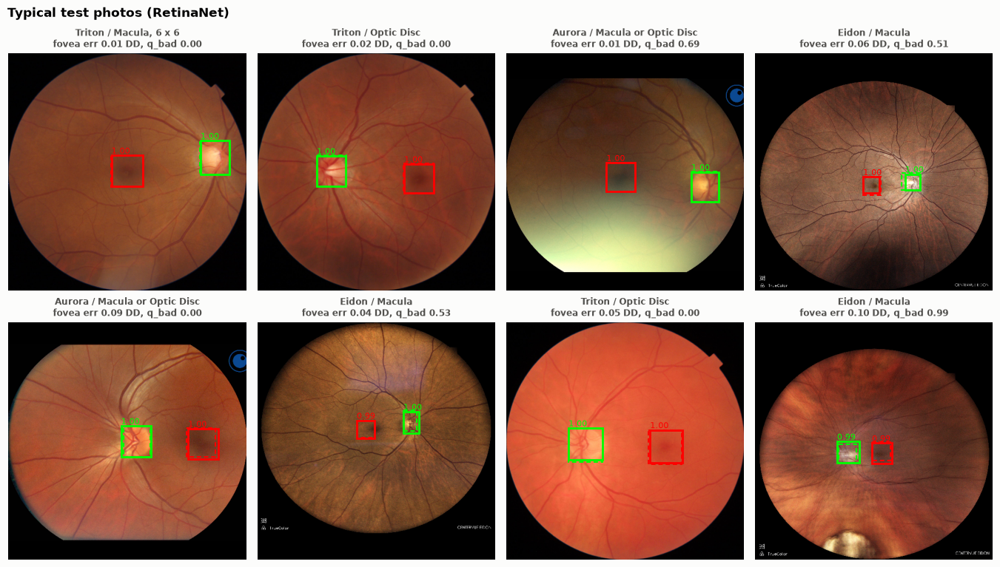

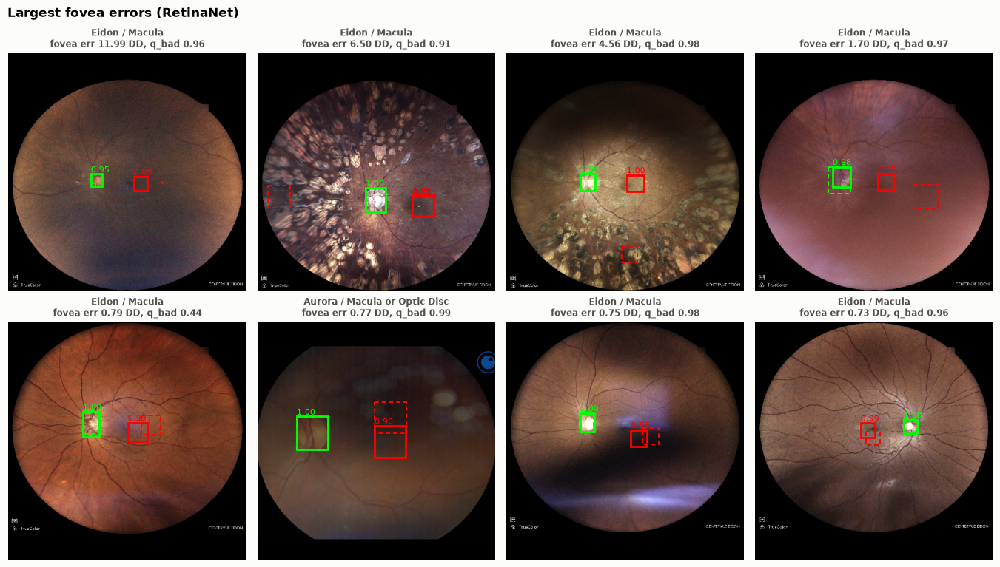

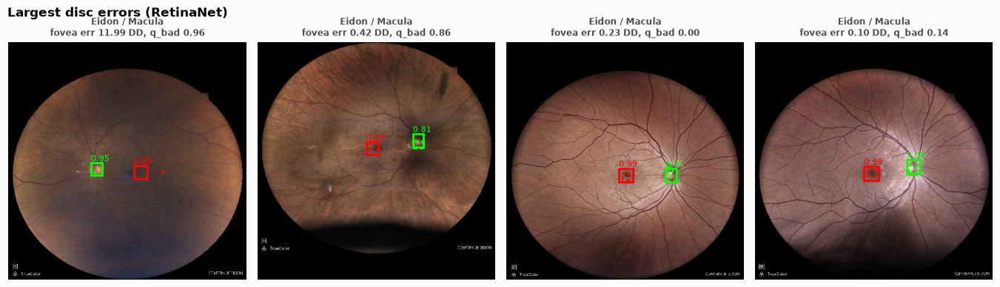

In [24]:
def show_pred(rows, arch, title="", ncols=4, name=None):
    """Crops with VascX boxes (dashed) and the model's top boxes (solid)."""
    rows = list(rows.itertuples())
    if not rows:
        print("nothing to show")
        return None
    nrows = (len(rows) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 4.0 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, rows):
        ax.imshow(CACHE_IMAGES[int(r.row)])
        for cls, colour in (("disc", "lime"), ("fovea", "red")):
            g = [getattr(r, f"gt_{cls}_{c}") for c in ("x0", "y0", "x1", "y1")]
            if not np.isnan(g[0]):
                ax.add_patch(Rectangle(g[:2], g[2] - g[0], g[3] - g[1], fill=False, ec=colour, lw=1.4, ls=(0, (3, 2))))
            p = [getattr(r, f"{cls}_{c}") for c in ("x0", "y0", "x1", "y1")]
            if not np.isnan(p[0]):
                ax.add_patch(Rectangle(p[:2], p[2] - p[0], p[3] - p[1], fill=False, ec=colour, lw=2))
                ax.text(p[0], p[1] - 4, f"{getattr(r, f'{cls}_score'):.2f}", color=colour, fontsize=8)
        err = r.fovea_centre_dd
        ax.set_title(f"{r.field}\nfovea err {err:.2f} DD, q_bad {r.q_bad:.2f}" if not np.isnan(err) else
                     f"{r.field}\nno VascX disc, q_bad {r.q_bad:.2f}", fontsize=8.5, color=INK_2)
    fig.suptitle(f"{title} ({NAMES[arch]})", x=0.01, ha="left", fontsize=12, weight="bold")
    fig.tight_layout()
    if name:
        save(fig, name)
    return fig


best = ARCHS[int(np.argmax([summary(kept[a])["fovea_iou"] for a in ARCHS]))]  # the better fovea model
k = kept[best]
show_pred(k.sample(8, random_state=1), best, "Typical test photos", name="fig4_typical")
show_pred(k.nlargest(8, "fovea_centre_dd"), best, "Largest fovea errors", name="fig5_worst_fovea")
show_pred(k.nlargest(4, "disc_centre_dd"), best, "Largest disc errors");

Eidon is the outlier in section 9. Its worst fovea cases, and a random handful for comparison:

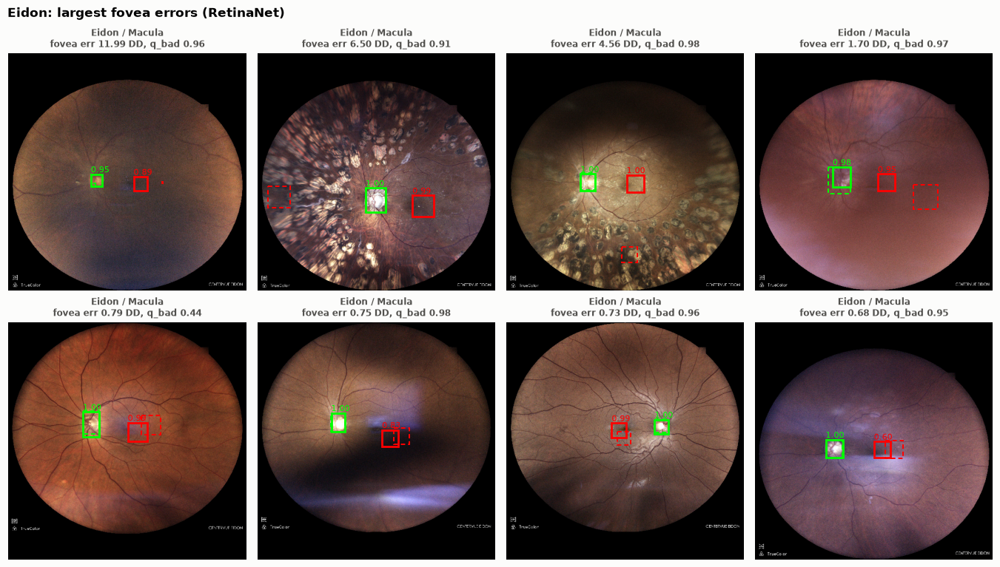

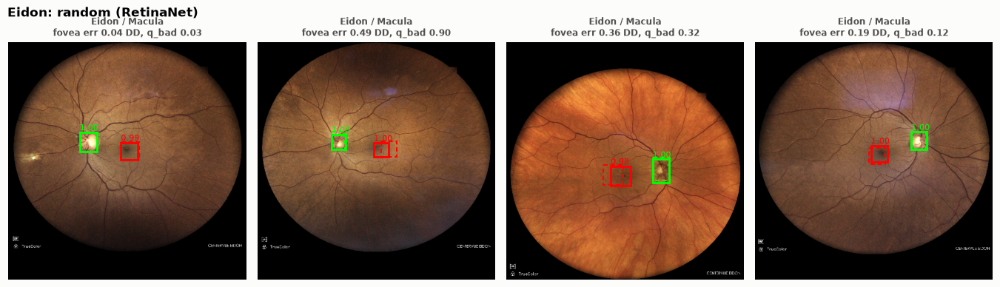

In [25]:
eidon = k[k.field.str.startswith("Eidon")]
show_pred(eidon.nlargest(8, "fovea_centre_dd"), best, "Eidon: largest fovea errors", name="fig6_eidon_worst")
show_pred(eidon.sample(4, random_state=0), best, "Eidon: random");

## 12. Outside the filter

The 319 test photos the filter dropped: VascX found no disc, found it in several pieces, or the quality model rated the
photo `q_bad > 0.99`. They have no trustworthy label, so no IoU, but the detector's **disc score** tells us whether it
could flag such photos on its own, which a deployed MAP will need (it sees every photo, not only filtered ones).

Faster R-CNN                                        \
                                photos disc_score_median disc_score_below_05   
group                                                                          
kept                              2046             1.000               0.000   
ungradable (q_bad > 0.99)          234             1.000               0.261   
VascX: disc in pieces               45             1.000               0.556   
VascX: no disc                      40             0.999               0.850   

                          RetinaNet                                        
                             photos disc_score_median disc_score_below_05  
group                                                                      
kept                           2046             1.000               0.000  
ungradable (q_bad > 0.99)       234             1.000               0.261  
VascX: disc in pieces            45             1.000               0.467  
VascX: no disc                   40             0.832               0.850

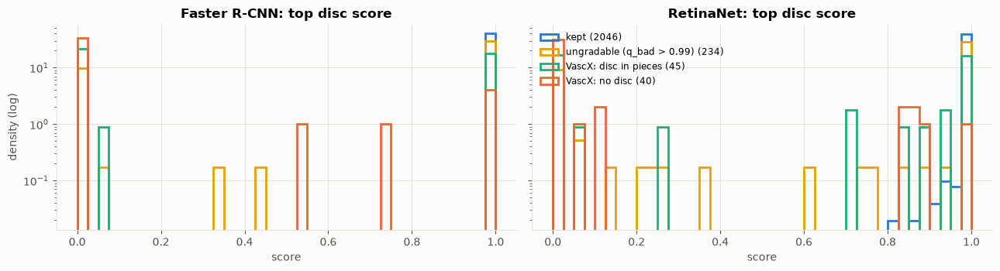

In [26]:
def group(p):
    return np.select([p.kept, p.disc_found != 1, p.disc_parts > 1], ["kept", "VascX: no disc", "VascX: disc in pieces"],
                     "ungradable (q_bad > 0.99)")


for a in ARCHS:
    pred[a]["group"] = group(pred[a])
GROUPS = ["kept", "ungradable (q_bad > 0.99)", "VascX: disc in pieces", "VascX: no disc"]
display(pd.concat({NAMES[a]: pred[a].groupby("group").agg(photos=("row", "size"),
                                                          disc_score_median=("disc_score", "median"),
                                                          disc_score_below_05=("disc_score", lambda s: (s.fillna(0) < 0.5).mean()))
                   for a in ARCHS}, axis=1).reindex(GROUPS).round(3))

fig, axes = plt.subplots(1, len(ARCHS), figsize=(6.5 * len(ARCHS), 3.6), sharey=True, squeeze=False)
for ax, a in zip(axes.flat, ARCHS):
    for g, colour in zip(GROUPS, ["#2a78d6", "#eda100", "#1baf7a", "#eb6834"]):
        s = pred[a].loc[pred[a].group == g, "disc_score"].fillna(0)
        ax.hist(s, bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=colour, density=True, label=f"{g} ({len(s)})")
    ax.set(title=f"{NAMES[a]}: top disc score", xlabel="score", yscale="log")
axes[0, 0].set_ylabel("density (log)")
axes[0, -1].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
save(fig, "fig7_scores_outside_filter")

Who's right when they disagree? Photos where VascX found **no disc** but the detector is confident, and dropped
photos where the detector is unsure:

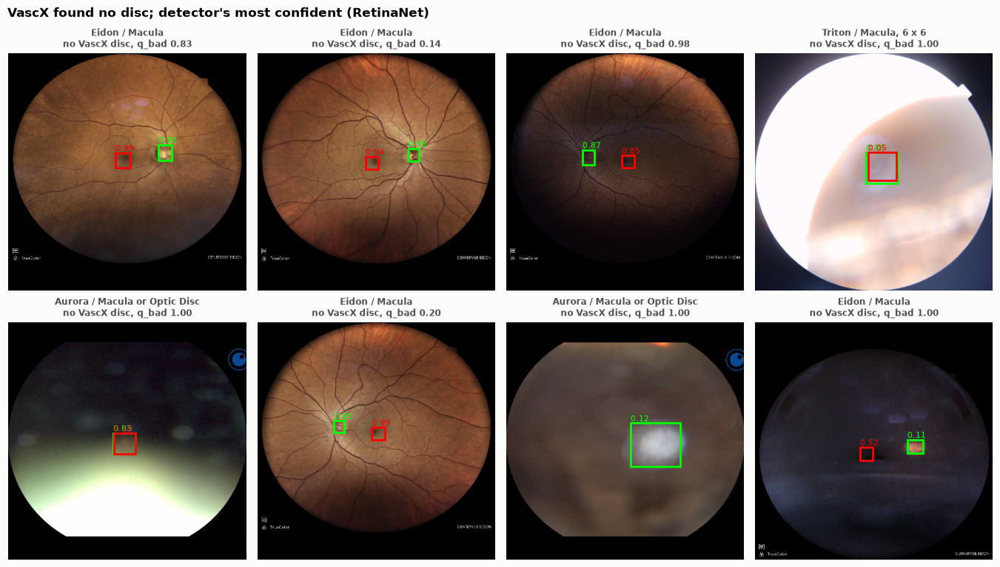

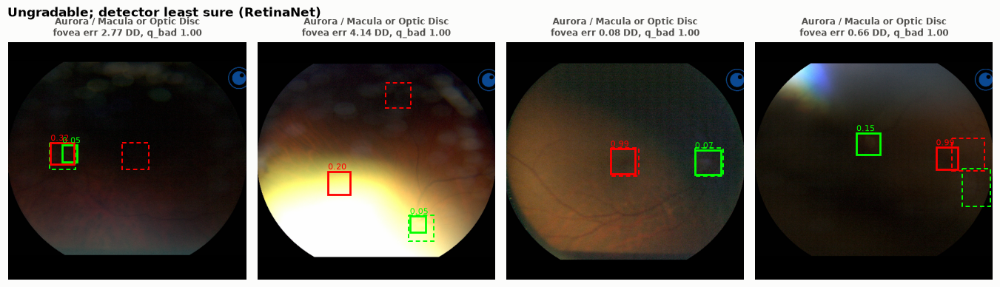

In [27]:
p = pred[best]
show_pred(p[(p.group == "VascX: no disc")].nlargest(8, "disc_score"), best, "VascX found no disc; detector's most confident",
          name="fig8_no_disc_confident")
show_pred(p[p.group == "ungradable (q_bad > 0.99)"].nsmallest(4, "disc_score"), best, "Ungradable; detector least sure");

## 13. Speed and size

Throughput is the model alone on the GPU (batch 16, crops already in memory); a MAP adds DICOM decoding and cropping
(~0.2 s per photo on one CPU core, see `prepare_cache.py`), which will dominate.

In [28]:
pd.DataFrame({NAMES[a]: {"photos per s": speed[a]["photos_per_s"], "ms per photo": round(1000 / speed[a]["photos_per_s"], 1),
                         "checkpoint MB": round((RUNS[a] / "best.pt").stat().st_size / 1e6), "GPU": speed[a]["gpu"],
                         "best epoch": speed[a]["epoch"]} for a in ARCHS}).T

,photos per s,ms per photo,checkpoint MB,GPU,best epoch
Faster R-CNN,37.1,27.0,173,NVIDIA RTX A4000,20
RetinaNet,80.6,12.4,146,NVIDIA RTX A4000,19


## 14. Takeaways (2026-11-06)

All against VascX's labels, not clinicians'; fovea numbers use VascX's point (see the Discussion before section 8).

- **Both detectors reproduce VascX closely.** On 2,046 test photos: disc IoU 0.935 (both), fovea IoU 0.84 (Faster R-CNN)
  vs 0.85 (RetinaNet). Disc centre within 0.5 DD of VascX's in 99.9 % of photos, fovea in 98.8 %. Median centre errors are
  0.01 DD (disc) and 0.04 DD (fovea): a few pixels.
- **No real winner on accuracy, a clear one on cost.** RetinaNet is 2.2× faster (81 vs 37 photos/s on an A4000) and 15 %
  smaller, with equal or slightly better fovea numbers. **RetinaNet is the one to take to a MAP.**
- **They miss the same photos.** 19 of the ~22 fovea misses are shared, which points at the photos (or the labels), not the
  architecture. 13 of the 19 are Eidon, 5 are Aurora.
- **Eidon's "misses" are mostly VascX's.** In the worst Eidon cases the detector's fovea sits at the dark macula and VascX's
  label is out in the periphery or on a lesion (section 11). The detector has learned something closer to the anatomy than
  its noisiest labels. Eidon's lower *disc* IoU (0.79) comes with 99 % of centres within 0.5 DD: the box location is right and
  the size differs. Eidon's disc is small in the 512 crop (wide field), and IoU punishes a few pixels of size error on a small box.
- **It finds discs VascX missed.** On clear Eidon photos where VascX found no disc, the detector puts a confident box on the
  disc (section 12). So "VascX: no disc" isn't a reliable negative, and those photos could go back into training.
- **The disc score is no quality gate.** On ungradable photos (`q_bad > 0.99`) the median disc score is still 1.00; only about a
  quarter score below 0.5. A deployed MAP needs the quality model (or its own) in front of the detector, not a score threshold.

**Next:** (1) hand-check ~100 photos (all 19 shared misses plus a random sample) to put a number on "detector right, VascX
wrong"; (2) consider returning the clear "VascX: no disc" photos to training; (3) MONAI RetinaNet on the same cache, for the
MONAI comparison; (4) RetinaNet + quality model as a MAP, as with laterality and VascX.

## 15. Slide prep

Every `save()` above writes `Stats/slides/<name>.png` and `.svg`. Suggested deck, one figure per slide:

| Slide | Figure | Message |
|---|---|---|
| 1 | (title) | Disc and fovea detection on AI-READI, trained on VascX labels |
| 2 | `../VascX_App/slides`-style pipeline, or a typical photo | Labels for free: VascX disc mask → disc box, fovea point → fovea box |
| 3 | `fig4_typical` | What the detector does |
| 4 | headline table (section 9) | Both detectors agree with VascX: 0.93 disc IoU, 0.85 fovea IoU; fovea within 0.5 DD in 99 % |
| 5 | `fig2_per_device` | Four devices near-perfect; Eidon is the gap |
| 6 | `fig3_centre_error_cdf` | Misses are rare and small, in disc diameters |
| 7 | `fig6_eidon_worst` | The biggest misses are mostly VascX's label errors |
| 8 | `fig8_no_disc_confident`, `fig7_scores_outside_filter` | It finds discs VascX missed, but its score is no quality gate |
| 9 | `fig1_training_curves` + speed table | Cost: 20 epochs, one GPU; RetinaNet ~2× faster |
| 10 | (text) | Next: hand-checked sample, MONAI RetinaNet, a MAP |

Photo figures (`fig4`–`fig6`, `fig8`) show AI-READI images: fine for an internal talk, but keep them out of git and
public decks.

In [29]:
for f in sorted(SLIDES.glob("*.png")):
    print(f"{f.name:40s} {f.stat().st_size / 1e3:7.0f} kB")

fig0_label_construction.png                  245 kB
fig1_training_curves.png                     194 kB
fig2_per_device.png                          111 kB
fig3_centre_error_cdf.png                     99 kB
fig4_typical.png                            4220 kB
fig5_worst_fovea.png                        4658 kB
fig6_eidon_worst.png                        4761 kB
fig7_scores_outside_filter.png                77 kB
fig8_no_disc_confident.png                  4355 kB
